In [12]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("COVID19_RQ2_MapReduce") \
    .getOrCreate()

sc = spark.sparkContext

from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType
)

import math
import time

# Load dataset
data_path = "../../covid.csv"

df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(data_path)
)

# Map phase
def mapper(row):

    country = row["countriesAndTerritories"]
    cases = row["cases_weekly"]
    deaths = row["deaths_weekly"]
    population = row["popData2019"]

    if country is None or cases is None or deaths is None:
        return None

    cases = float(cases)
    deaths = float(deaths)

    if population is not None and float(population) > 0:
        population = float(population)
    else:
        population = None

    return (
        country,
        (cases, deaths, population, population)
    )


mapped = (
    df.select(
        "countriesAndTerritories",
        "cases_weekly",
        "deaths_weekly",
        "popData2019"
    )
    .rdd
    .map(mapper)
    .filter(lambda x: x is not None)
)

In [13]:
# Reduce phase
def reducer(a, b):

    # Sum weekly cases and deaths
    total_cases = a[0] + b[0]
    total_deaths = a[1] + b[1]

    # Retain valid population values
    valid_min = [p for p in (a[2], b[2]) if p is not None]
    valid_max = [p for p in (a[3], b[3]) if p is not None]

    min_population = min(valid_min) if valid_min else None
    max_population = max(valid_max) if valid_max else None

    return (
        total_cases,
        total_deaths,
        min_population,
        max_population
    )


reduced = mapped.reduceByKey(reducer)

In [17]:
# Build final country-level records
results = reduced.map(
    lambda x: (
        x[0],
        x[1][0],
        x[1][1],
        x[1][2] if x[1][2] == x[1][3] else None
    )
)

schema = StructType([
    StructField("country", StringType(), False),
    StructField("total_cases", DoubleType(), False),
    StructField("total_deaths", DoubleType(), False),
    StructField("population", DoubleType(), True)
])

final_df = spark.createDataFrame(results, schema)
final_df = final_df.orderBy("country")

for country, total_cases, total_deaths, population in final_df.orderBy("country").limit(5).collect():
    print("{}\t{}\t{}\t{}".format(
        country,
        total_cases,
        total_deaths,
        population if population is not None else "NA"
    ))

print()

for country, total_cases, total_deaths, population in (
    final_df.orderBy("country", ascending=False).limit(5).collect()[::-1]
):
    print("{}\t{}\t{}\t{}".format(
        country,
        total_cases,
        total_deaths,
        population if population is not None else "NA"
    ))

Afghanistan	55359.0	2413.0	38041757.0
Albania	85336.0	1460.0	2862427.0
Algeria	109088.0	2914.0	43053054.0
Andorra	10251.0	106.0	76177.0
Angola	20086.0	475.0	31825299.0

Wallis_and_Futuna	9.0	0.0	NA
Western_Sahara	766.0	1.0	582458.0
Yemen	2131.0	616.0	29161922.0
Zambia	62633.0	853.0	17861034.0
Zimbabwe	34552.0	1326.0	14645473.0


In [24]:
import time

start_time = time.time()

# MAP
mapped = (
    df.select(
        "countriesAndTerritories",
        "cases_weekly",
        "deaths_weekly",
        "popData2019"
    )
    .rdd
    .map(mapper)
    .filter(lambda x: x is not None)
)

# SHUFFLE + REDUCE
reduced = mapped.reduceByKey(reducer)

# Force Spark to execute the computation
results = reduced.collect()

end_time = time.time()

execution_time = end_time - start_time

print("MapReduce execution time: {:.4f} seconds".format(execution_time))

MapReduce execution time: 0.4927 seconds


In [25]:
# FOR PEARSON
from pyspark.sql.functions import col, isnan

analysis_df = (
    final_df
    .dropna(subset=[
        "population",
        "total_cases",
        "total_deaths"
    ])
    .filter(
        (col("population") > 0) &
        (~isnan(col("population"))) &
        (~isnan(col("total_cases"))) &
        (~isnan(col("total_deaths")))
    )
)

n_countries = analysis_df.count()

print("Number of countries:", n_countries)

Number of countries: 213


In [26]:
pearson_cases = analysis_df.stat.corr(
    "population",
    "total_cases",
    method="pearson"
)

pearson_deaths = analysis_df.stat.corr(
    "population",
    "total_deaths",
    method="pearson"
)

print("Population vs total cases: {:.4f}".format(pearson_cases))
print("Population vs total deaths: {:.4f}".format(pearson_deaths))

Population vs total cases: 0.3977
Population vs total deaths: 0.3567


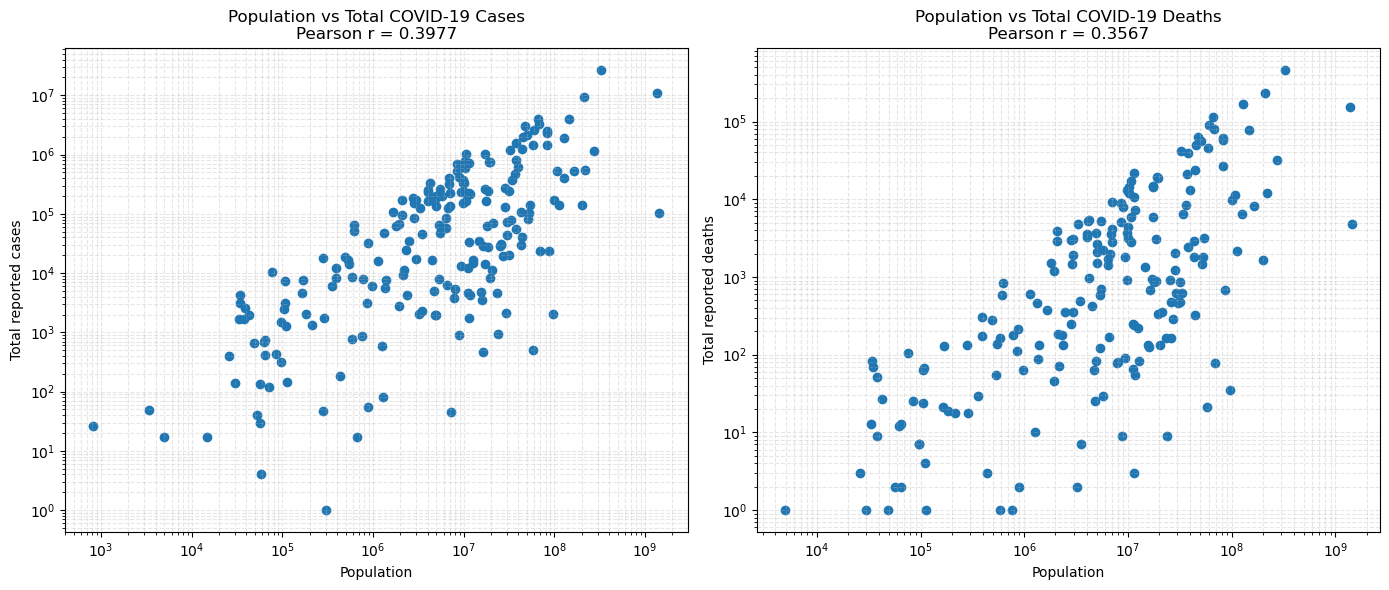

In [28]:
import matplotlib.pyplot as plt

# Collect country-level results from Spark
plot_data = analysis_df.select(
    "population",
    "total_cases",
    "total_deaths"
).collect()

populations = [row["population"] for row in plot_data]
cases = [row["total_cases"] for row in plot_data]
deaths = [row["total_deaths"] for row in plot_data]

# Keep strictly positive values for logarithmic axes
cases_data = [
    (p, c) for p, c in zip(populations, cases)
    if p > 0 and c > 0
]

deaths_data = [
    (p, d) for p, d in zip(populations, deaths)
    if p > 0 and d > 0
]

# Create the two scatterplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Population vs cases
axes[0].scatter(
    [x[0] for x in cases_data],
    [x[1] for x in cases_data]
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title(
    "Population vs Total COVID-19 Cases\nPearson r = {:.4f}".format(pearson_cases)
)
axes[0].set_xlabel("Population")
axes[0].set_ylabel("Total reported cases")
axes[0].grid(True, which="both", linestyle="--", alpha=0.3)

# Population vs deaths
axes[1].scatter(
    [x[0] for x in deaths_data],
    [x[1] for x in deaths_data]
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title(
    "Population vs Total COVID-19 Deaths\nPearson r = {:.4f}".format(pearson_deaths)
)
axes[1].set_xlabel("Population")
axes[1].set_ylabel("Total reported deaths")
axes[1].grid(True, which="both", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()